## Urinary biomarkers for pancreatic cancer


# 1. Data description

In [496]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier,
    VotingClassifier,
 )
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    log_loss,
    roc_auc_score,
    roc_curve,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression())
])
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.tree import DecisionTreeClassifier, export_text
import warnings

# Optional import for XGBoost; provide a graceful fallback if not installed
try:
    from xgboost import XGBClassifier
except ModuleNotFoundError:
    XGBClassifier = None
    print("Optional dependency 'xgboost' is not installed. Install with: pip install xgboost")

warnings.filterwarnings('ignore')

In [497]:
df = pd.read_csv('Debernardi et al 2020 data.csv')


In [498]:
df.shape

(590, 14)

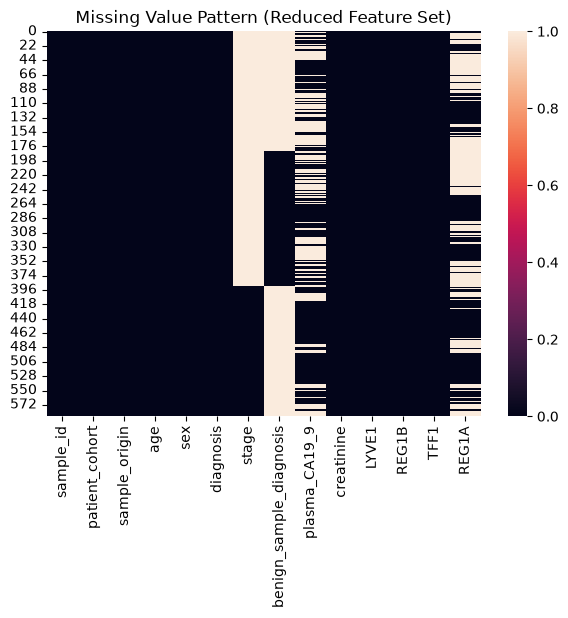

<Figure size 1200x1000 with 0 Axes>

<Figure size 1200x1000 with 0 Axes>

In [499]:
plt.figure(figsize=(7, 5), dpi=100)
sns.heatmap(df.isna())
plt.title("Missing Value Pattern (Reduced Feature Set)")
plt.show()
plt.figure(figsize=(12, 10))

In [500]:
# Missing values in columns
df.isnull().sum()


sample_id                    0
patient_cohort               0
sample_origin                0
age                          0
sex                          0
diagnosis                    0
stage                      391
benign_sample_diagnosis    382
plasma_CA19_9              240
creatinine                   0
LYVE1                        0
REG1B                        0
TFF1                         0
REG1A                      284
dtype: int64

In [501]:
# Missing value percentage in columns
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing %": df.isnull().mean() * 100
})
missing

,Missing Values,Missing %
sample_id,0,0.000000
patient_cohort,0,0.000000
sample_origin,0,0.000000
age,0,0.000000
sex,0,0.000000
diagnosis,0,0.000000
stage,391,66.271186
benign_sample_diagnosis,382,64.745763
plasma_CA19_9,240,40.677966
creatinine,0,0.000000


In [502]:
# Missing values in rows
df[df.isnull().any(axis=1)]


,sample_id,patient_cohort,sample_origin,age,sex,diagnosis,stage,benign_sample_diagnosis,plasma_CA19_9,creatinine,LYVE1,REG1B,TFF1,REG1A
0,S1,Cohort1,BPTB,33,F,1,NaN,NaN,11.7,1.83222,0.893219,52.948840,654.282174,1262.000
1,S10,Cohort1,BPTB,81,F,1,NaN,NaN,NaN,0.97266,2.037585,94.467030,209.488250,228.407
2,S100,Cohort2,BPTB,51,M,1,NaN,NaN,7.0,0.78039,0.145589,102.366000,461.141000,NaN
3,S101,Cohort2,BPTB,61,M,1,NaN,NaN,8.0,0.70122,0.002805,60.579000,142.950000,NaN
4,S102,Cohort2,BPTB,62,M,1,NaN,NaN,9.0,0.21489,0.000860,65.540000,41.088000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
585,S549,Cohort2,BPTB,68,M,3,IV,NaN,NaN,0.52026,7.058209,156.241000,525.178000,NaN
586,S558,Cohort2,BPTB,71,F,3,IV,NaN,NaN,0.85956,8.341207,16.915000,245.947000,NaN
587,S560,Cohort2,BPTB,63,M,3,IV,NaN,NaN,1.36851,7.674707,289.701000,537.286000,NaN
588,S583,Cohort2,BPTB,75,F,3,IV,NaN,NaN,1.33458,8.206777,205.930000,722.523000,NaN


In [503]:
# Number of missing values in rows
df[df.isnull().any(axis=1)].shape[0]


590

In [504]:
missing_rows = df[df.isnull().any(axis=1)]

print(missing_rows)


    sample_id patient_cohort sample_origin  age sex  diagnosis stage  \
0          S1        Cohort1          BPTB   33   F          1   NaN   
1         S10        Cohort1          BPTB   81   F          1   NaN   
2        S100        Cohort2          BPTB   51   M          1   NaN   
3        S101        Cohort2          BPTB   61   M          1   NaN   
4        S102        Cohort2          BPTB   62   M          1   NaN   
..        ...            ...           ...  ...  ..        ...   ...   
585      S549        Cohort2          BPTB   68   M          3    IV   
586      S558        Cohort2          BPTB   71   F          3    IV   
587      S560        Cohort2          BPTB   63   M          3    IV   
588      S583        Cohort2          BPTB   75   F          3    IV   
589      S590        Cohort1          BPTB   74   M          3    IV   

    benign_sample_diagnosis  plasma_CA19_9  creatinine     LYVE1       REG1B  \
0                       NaN           11.7     1.83222 

## 1a. Cleaning the Data



In [505]:
# Drop the identifier column
df.drop(columns=['sample_id'], inplace=True)

### Cohort Column

In [506]:
# change cohort column values to integers for modeling
display(df["patient_cohort"].value_counts(dropna=False))

patient_cohort
Cohort1    332
Cohort2    258
Name: count, dtype: int64

In [507]:
df["patient_cohort"] = df["patient_cohort"].map({
    "Cohort1": 1,
    "Cohort2": 2
})
display(df["patient_cohort"].value_counts(dropna=False))

patient_cohort
1    332
2    258
Name: count, dtype: int64

## 1b. Imputation of the data

In [508]:
# Change sex column to numerical values for modeling
df["sex"] = df["sex"].map({"M": 1, "F": 2})
display(df["sex"].value_counts(dropna=False))

sex
2    299
1    291
Name: count, dtype: int64

### Stage column

In [509]:
# Change stage column to numerical values for modeling
display(df["stage"])

0      NaN
1      NaN
2      NaN
3      NaN
4      NaN
      ... 
585     IV
586     IV
587     IV
588     IV
589     IV
Name: stage, Length: 590, dtype: str

In [510]:
# Values in stage column
display(df["stage"].unique())


<StringArray>
[nan, 'I', 'IA', 'IB', 'II', 'IIA', 'IIB', 'III', 'IV']
Length: 9, dtype: str

In [511]:
# Information of stage column
display(df["stage"].value_counts(dropna=False))

stage
NaN    391
III     76
IIB     68
IV      21
IB      12
IIA     11
II       7
IA       3
I        1
Name: count, dtype: int64

In [512]:
display(df["stage"].value_counts(dropna=False))

stage
NaN    391
III     76
IIB     68
IV      21
IB      12
IIA     11
II       7
IA       3
I        1
Name: count, dtype: int64

### Replace NaN values in stage column with 0
Because according to the data "stage" column values correspond to,"The stage of pancratic cancer". That are IA, IB, IIA, IIIB, III, IV and NaN. From here we assume NaN means patients with no cancer. So to replace the stage of cancer values with integers, we would replace Nan with 0, IA with 1, IB with 2 and so on.  

In [513]:
print(df["stage"].unique())

<StringArray>
[nan, 'I', 'IA', 'IB', 'II', 'IIA', 'IIB', 'III', 'IV']
Length: 9, dtype: str


In [514]:
# Replace stage column values with integers for modeling
df["stage"] = df["stage"].map({
    "I": 1,
    "IA": 2,
    "IB": 3,
    "II": 4,
    "IIA": 5,
    "IIB": 6,
    "III": 7,
    "IV": 8,
    
}).fillna(0)


In [515]:
# replace the stage column values with integers for modeling
display(df["stage"].value_counts(dropna=False))

stage
0.0    391
7.0     76
6.0     68
8.0     21
3.0     12
5.0     11
4.0      7
2.0      3
1.0      1
Name: count, dtype: int64

In [516]:
# Fixed placeholder cell (previously corrupted)
df.head()

,patient_cohort,sample_origin,age,sex,diagnosis,stage,benign_sample_diagnosis,plasma_CA19_9,creatinine,LYVE1,REG1B,TFF1,REG1A
0,1,BPTB,33,2,1,0.0,NaN,11.7,1.83222,0.893219,52.94884,654.282174,1262.000
1,1,BPTB,81,2,1,0.0,NaN,NaN,0.97266,2.037585,94.46703,209.488250,228.407
2,2,BPTB,51,1,1,0.0,NaN,7.0,0.78039,0.145589,102.36600,461.141000,NaN
3,2,BPTB,61,1,1,0.0,NaN,8.0,0.70122,0.002805,60.57900,142.950000,NaN
4,2,BPTB,62,1,1,0.0,NaN,9.0,0.21489,0.000860,65.54000,41.088000,NaN


# Classification of diagnosis column
1 → 0 = Healthy
2 → 1 = Benign / Pancreatitis
3 → 2 = Pancreatic cancer


In [517]:
# Classify the diagnosis column values with integers for modeling
display(df["diagnosis"].value_counts(dropna=False))


diagnosis
2    208
3    199
1    183
Name: count, dtype: int64

In [518]:
# Classify the diagnosis column values with integers for modeling
print(df["diagnosis"].unique())

[1 2 3]


In [519]:
# Classify the diagnosis column values with integers for modeling
df["diagnosis"] = df["diagnosis"].map({
    1: 0,
    2: 1,
    3: 2
})
display(df["diagnosis"].value_counts(dropna=False))

diagnosis
1    208
2    199
0    183
Name: count, dtype: int64

In [520]:
df.drop(columns=['stage', 'benign_sample_diagnosis'], inplace=True)
df.head(20)

,patient_cohort,sample_origin,age,sex,diagnosis,plasma_CA19_9,creatinine,LYVE1,REG1B,TFF1,REG1A
0,1,BPTB,33,2,0,11.7,1.83222,0.893219,52.94884,654.282174,1262.000
1,1,BPTB,81,2,0,NaN,0.97266,2.037585,94.46703,209.488250,228.407
2,2,BPTB,51,1,0,7.0,0.78039,0.145589,102.36600,461.141000,NaN
3,2,BPTB,61,1,0,8.0,0.70122,0.002805,60.57900,142.950000,NaN
4,2,BPTB,62,1,0,9.0,0.21489,0.000860,65.54000,41.088000,NaN
5,2,BPTB,53,1,0,NaN,0.84825,0.003393,62.12600,59.793000,NaN
6,2,BPTB,70,1,0,NaN,0.62205,0.174381,152.27700,117.516000,NaN
7,2,BPTB,58,2,0,11.0,0.89349,0.003574,3.73000,40.294000,NaN
8,2,BPTB,59,2,0,NaN,0.48633,0.001945,7.02100,26.782000,NaN
9,2,BPTB,56,2,0,24.0,0.61074,0.278778,83.92800,19.185000,NaN


In [521]:
columns_to_check = [
    "plasma_CA19_9",
    "creatinine",
    "LYVE1",
    "REG1B",
    "TFF1",
    "REG1A"
]

df[columns_to_check].isnull().sum()

plasma_CA19_9    240
creatinine         0
LYVE1              0
REG1B              0
TFF1               0
REG1A            284
dtype: int64

In [522]:
#Investigate missing values in biomarkers columns by diagnosis column
df.groupby("diagnosis")[columns_to_check].apply(
    lambda x: x.isnull().sum()
)

,plasma_CA19_9,creatinine,LYVE1,REG1B,TFF1,REG1A
diagnosis,,,,,,
0,91,0,0,0,0,104
1,100,0,0,0,0,121
2,49,0,0,0,0,59


In [523]:
df.columns.isnull() 

array([False, False, False, False, False, False, False, False, False,
       False, False])

In [524]:
df[df[columns_to_check].isna().any(axis=1)][columns_to_check]

,plasma_CA19_9,creatinine,LYVE1,REG1B,TFF1,REG1A
1,NaN,0.97266,2.037585,94.46703,209.48825,228.407
2,7.0,0.78039,0.145589,102.36600,461.14100,NaN
3,8.0,0.70122,0.002805,60.57900,142.95000,NaN
4,9.0,0.21489,0.000860,65.54000,41.08800,NaN
5,NaN,0.84825,0.003393,62.12600,59.79300,NaN
...,...,...,...,...,...,...
584,NaN,0.93873,7.085637,815.13600,2367.59000,NaN
585,NaN,0.52026,7.058209,156.24100,525.17800,NaN
586,NaN,0.85956,8.341207,16.91500,245.94700,NaN
587,NaN,1.36851,7.674707,289.70100,537.28600,NaN


# Pipeline generation

In [525]:
numeric_features = ["age", "plasma_CA19_9", "creatinine", "LYVE1", "REG1B", "TFF1", "REG1A"]
categorical_features = ["sex", "patient_cohort"]

# Keep only features that exist in the dataframe
missing_num = [c for c in numeric_features if c not in df.columns]
missing_cat = [c for c in categorical_features if c not in df.columns]
if missing_num or missing_cat:
    print("Warning: the following features are missing and will be ignored:")
    if missing_num:
        print("  numeric:", missing_num)
    if missing_cat:
        print("  categorical:", missing_cat)

numeric_features = [c for c in numeric_features if c in df.columns]
categorical_features = [c for c in categorical_features if c in df.columns]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])  
preprocess = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features),
])

preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

# Define x and y

In [526]:
y = df["diagnosis"]
X = df.drop(columns=["diagnosis"])

# Baseline Logistic model/ Test-Train

In [527]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")
print(f"Distribution test: {y_test.value_counts(normalize=True).round(3).to_dict()}")

Train shape: (472, 10), Test shape: (118, 10)
Distribution test: {1: 0.347, 2: 0.339, 0: 0.314}


In [528]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

class_names = ["0 = Healthy", "1 = Benign", "2 = Pancreatic Cancer"]

## 1. Multinomial Logistic Regression

In [529]:


# Logistic Regression pipeline
LogRegression_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Model fit
LogRegression_pipeline.fit(X_train, y_train)

# Prediction
y_pred = LogRegression_pipeline.predict(X_test)



# Test-set evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["0=Healthy", "1=Benign", "2=Pancreatic Cancer"]
    )
)

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)



Accuracy: 0.7542372881355932

Classification Report:
                     precision    recall  f1-score   support

          0=Healthy       0.67      0.81      0.73        37
           1=Benign       0.78      0.61      0.68        41
2=Pancreatic Cancer       0.83      0.85      0.84        40

           accuracy                           0.75       118
          macro avg       0.76      0.76      0.75       118
       weighted avg       0.76      0.75      0.75       118


Confusion Matrix:
[[30  4  3]
 [12 25  4]
 [ 3  3 34]]


## Cross-validation 5-fold

In [530]:
# 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro", 
    "roc_auc_ovr_weighted"
]

cv_results = cross_validate(
    LogRegression_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)
# Cross-validation results
print("\n--- Cross-validation results (5-Folds) ---")

for metric in scoring:
    mean_score = cv_results[f"test_{metric}"].mean()
    std_score = cv_results[f"test_{metric}"].std()

    print(f"{metric}: {mean_score:.4f} ± {std_score:.4f}")


--- Cross-validation results (5-Folds) ---
accuracy: 0.6080 ± 0.0302
precision_macro: 0.6141 ± 0.0327
recall_macro: 0.6124 ± 0.0315
f1_macro: 0.6088 ± 0.0312
roc_auc_ovr_weighted: 0.7999 ± 0.0178


In [531]:
#save aseline result
baseline_results = {
    "Model": "Logistic Regression",
    "CV Accuracy": cv_results["test_accuracy"].mean(),
    "CV Precision": cv_results["test_precision_macro"].mean(),
    "CV Recall": cv_results["test_recall_macro"].mean(),
    "CV F1": cv_results["test_f1_macro"].mean(),
    "Test Accuracy": accuracy_score(y_test, y_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "Test Macro F1": f1_score(y_test, y_pred, average="macro")
}

baseline_results

{'Model': 'Logistic Regression',
 'CV Accuracy': np.float64(0.607973124300112),
 'CV Precision': np.float64(0.6140786278700301),
 'CV Recall': np.float64(0.6124299974818525),
 'CV F1': np.float64(0.6087774352399657),
 'Test Accuracy': 0.7542372881355932,
 'Test Balanced Accuracy': 0.7568556361239288,
 'Test Macro F1': 0.7520483322539974}

# 2. Decision Tree



In [532]:
from sklearn.tree import DecisionTreeClassifier

DecisionTree_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("classifier", DecisionTreeClassifier(random_state=42))
])
# Fit the model
DecisionTree_pipeline.fit(X_train, y_train)

# Cross-validation for Decision Tree
dt_cv = cross_validate(
    DecisionTree_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
)

# Predict
y_pred_dt = DecisionTree_pipeline.predict(X_test)

print("Decision Tree Test Accuracy:", accuracy_score(y_test, y_pred_dt))

print("Decision Tree Cross-Validation")
for metric in scoring:
    mean_score = dt_cv[f"test_{metric}"].mean()
    std_score = dt_cv[f"test_{metric}"].std()
    print(f"{metric}: {mean_score:.4f} ± {std_score:.4f}")

Decision Tree Test Accuracy: 0.6864406779661016
Decision Tree Cross-Validation
accuracy: 0.6419 ± 0.0545
precision_macro: 0.6440 ± 0.0583
recall_macro: 0.6429 ± 0.0548
f1_macro: 0.6421 ± 0.0560
roc_auc_ovr_weighted: 0.7306 ± 0.0410


# 3. Random Forest

In [533]:

RandomForest_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])
RandomForest_pipeline.fit(X_train, y_train)

# Cross-validation for Random Forest
rf_cv = cross_validate(
    RandomForest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
)
y_pred_rf = RandomForest_pipeline.predict(X_test)
print("Random Forest Test Accuracy:", accuracy_score(y_test, y_pred_rf))

print("Random Forest Cross-Validation")
for metric in scoring:
    mean_score = rf_cv[f"test_{metric}"].mean()
    std_score = rf_cv[f"test_{metric}"].std()
    print(f"{metric}: {mean_score:.4f} ± {std_score:.4f}")

Random Forest Test Accuracy: 0.7542372881355932
Random Forest Cross-Validation
accuracy: 0.7162 ± 0.0341
precision_macro: 0.7228 ± 0.0292
recall_macro: 0.7171 ± 0.0354
f1_macro: 0.7169 ± 0.0338
roc_auc_ovr_weighted: 0.8723 ± 0.0248


In [534]:
X_train, y_train

(     patient_cohort sample_origin  age  sex  plasma_CA19_9  creatinine  \
 55                2          BPTB   49    1        2.11638     0.91611   
 423               1          BPTB   73    2      354.00000     0.15834   
 481               2          BPTB   70    2            NaN     0.61074   
 247               2          BPTB   40    1            NaN     1.01790   
 335               1           UCL   71    1            NaN     1.19886   
 ..              ...           ...  ...  ...            ...         ...   
 223               2          BPTB   75    1            NaN     0.46371   
 455               1           LIV   62    1       62.00000     0.53157   
 475               2          BPTB   71    1      434.00000     0.11310   
 6                 2          BPTB   70    1            NaN     0.62205   
 117               2          BPTB   37    1            NaN     0.71253   
 
         LYVE1       REG1B         TFF1     REG1A  
 55   0.013293   78.470300    13.293490       

# AdaBoost

In [535]:
AdaBoost_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("classifier", AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    ))
])
# fit the AdaBoost model
AdaBoost_pipeline.fit(X_train, y_train)
# Predict
y_pred_ada = AdaBoost_pipeline.predict(X_test)

# Evaluate the model
print("AdaBoost Accuracy:",
      accuracy_score(y_test, y_pred_ada))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_ada,
    target_names=["Healthy", "Benign", "Cancer"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_ada))

# Cross-validation for AdaBoost
ada_cv = cross_validate(
    AdaBoost_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("AdaBoost Cross-Validation")

for metric in scoring:
    mean_score = ada_cv[f"test_{metric}"].mean()
    std_score = ada_cv[f"test_{metric}"].std()

    print(
        f"{metric}: "
        f"{mean_score:.4f} ± {std_score:.4f}"
    )

AdaBoost Accuracy: 0.7457627118644068

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.68      0.76      0.72        37
      Benign       0.68      0.61      0.64        41
      Cancer       0.88      0.88      0.88        40

    accuracy                           0.75       118
   macro avg       0.74      0.75      0.74       118
weighted avg       0.75      0.75      0.74       118


Confusion Matrix:
[[28  8  1]
 [12 25  4]
 [ 1  4 35]]
AdaBoost Cross-Validation
accuracy: 0.6398 ± 0.0220
precision_macro: 0.6476 ± 0.0340
recall_macro: 0.6428 ± 0.0197
f1_macro: 0.6418 ± 0.0240
roc_auc_ovr_weighted: 0.7909 ± 0.0189


# Gradient Boosting

In [536]:
GradientBoosting_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])
# fit the Gradient Boosting model
GradientBoosting_pipeline.fit(X_train, y_train)

# Predict
y_pred_gb = GradientBoosting_pipeline.predict(X_test)

# Evaluate the model
print("Gradient Boosting Accuracy:",
      accuracy_score(y_test, y_pred_gb))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_gb,
    target_names=["Healthy", "Benign", "Cancer"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

# cross-validation for Gradient Boosting
gb_cv = cross_validate(
    GradientBoosting_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("Gradient Boosting Cross-Validation")

for metric in scoring:
    mean_score = gb_cv[f"test_{metric}"].mean()
    std_score = gb_cv[f"test_{metric}"].std()

    print(
        f"{metric}: "
        f"{mean_score:.4f} ± {std_score:.4f}"
    )

Gradient Boosting Accuracy: 0.7711864406779662

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.75      0.73      0.74        37
      Benign       0.69      0.66      0.68        41
      Cancer       0.86      0.93      0.89        40

    accuracy                           0.77       118
   macro avg       0.77      0.77      0.77       118
weighted avg       0.77      0.77      0.77       118


Confusion Matrix:
[[27  9  1]
 [ 9 27  5]
 [ 0  3 37]]
Gradient Boosting Cross-Validation
accuracy: 0.6653 ± 0.0325
precision_macro: 0.6697 ± 0.0381
recall_macro: 0.6665 ± 0.0321
f1_macro: 0.6663 ± 0.0344
roc_auc_ovr_weighted: 0.8426 ± 0.0165


# XGBoost

In [537]:
# XGBoost (use RandomForest fallback if xgboost isn't installed)
if XGBClassifier is None:
    print("xgboost not installed — using RandomForestClassifier as a fallback for tree-based model")
    XGBoost_pipeline = Pipeline([
        ("preprocess", preprocess),
        ("classifier", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))
    ])
else:
    XGBoost_pipeline = Pipeline([
        ("preprocess", preprocess),
        ("classifier", XGBClassifier(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=3,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            num_class=3,
            eval_metric="mlogloss",
            use_label_encoder=False,
            random_state=42
        ))
    ])

# Fit the model
XGBoost_pipeline.fit(X_train, y_train)

# Predict the model
y_pred_xgb = XGBoost_pipeline.predict(X_test)

# Evaluate
print("XGBoost/Tree-based Model Accuracy:", accuracy_score(y_test, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=["Healthy", "Benign", "Cancer"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

# cross-validation of the model
xgb_cv = cross_validate(
    XGBoost_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("XGBoost/Tree-based Model Cross-Validation")

for metric in scoring:
    mean_score = xgb_cv[f"test_{metric}"].mean()
    std_score = xgb_cv[f"test_{metric}"].std()

    print(
        f"{metric}: "
        f"{mean_score:.4f} ± {std_score:.4f}"
    )

XGBoost/Tree-based Model Accuracy: 0.7711864406779662

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.71      0.78      0.74        37
      Benign       0.74      0.61      0.67        41
      Cancer       0.86      0.93      0.89        40

    accuracy                           0.77       118
   macro avg       0.77      0.77      0.77       118
weighted avg       0.77      0.77      0.77       118


Confusion Matrix:
[[29  6  2]
 [12 25  4]
 [ 0  3 37]]
XGBoost/Tree-based Model Cross-Validation
accuracy: 0.6928 ± 0.0373
precision_macro: 0.6938 ± 0.0421
recall_macro: 0.6944 ± 0.0358
f1_macro: 0.6926 ± 0.0396
roc_auc_ovr_weighted: 0.8513 ± 0.0221


## Comparison of the models


In [538]:
def evaluate_model(model_name, cv_results, y_test, y_pred):
    return {
        "Model": model_name,
        "CV Accuracy Mean": cv_results["test_accuracy"].mean(),
        "CV Accuracy SD": cv_results["test_accuracy"].std(),
        "CV Precision Macro Mean": cv_results["test_precision_macro"].mean(),
        "CV Recall Macro Mean": cv_results["test_recall_macro"].mean(),
        "CV F1 Macro Mean": cv_results["test_f1_macro"].mean(),
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision Macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Test Recall Macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "Test F1 Macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
    }

In [539]:
results = []

# 1. Logistic Regression
results.append(
    evaluate_model(
        "Logistic Regression",
        cv_results,
        y_test,
        y_pred
    )
)

# 2. Decision Tree
results.append(
    evaluate_model(
        "Decision Tree",
        dt_cv,
        y_test,
        y_pred_dt
    )
)

# 3. Random Forest
results.append(
    evaluate_model(
        "Random Forest",
        rf_cv,
        y_test,
        y_pred_rf
    )
)

# 4. AdaBoost
results.append(
    evaluate_model(
        "AdaBoost",
        ada_cv,
        y_test,
        y_pred_ada
    )
)

# 5. Gradient Boosting
results.append(
    evaluate_model(
        "Gradient Boosting",
        gb_cv,
        y_test,
        y_pred_gb
    )
)

# 6. XGBoost
results.append(
    evaluate_model(
        "XGBoost",
        xgb_cv,
        y_test,
        y_pred_xgb
    )
)

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.round(4)

display(comparison_df)

,Model,CV Accuracy Mean,CV Accuracy SD,CV Precision Macro Mean,CV Recall Macro Mean,CV F1 Macro Mean,Test Accuracy,Test Precision Macro,Test Recall Macro,Test F1 Macro
0,Logistic Regression,0.6080,0.0302,0.6141,0.6124,0.6088,0.7542,0.7591,0.7569,0.7520
1,Decision Tree,0.6419,0.0545,0.6440,0.6429,0.6421,0.6864,0.6863,0.6897,0.6828
2,Random Forest,0.7162,0.0341,0.7228,0.7171,0.7169,0.7542,0.7544,0.7513,0.7492
3,AdaBoost,0.6398,0.0220,0.6476,0.6428,0.6418,0.7458,0.7445,0.7472,0.7447
4,Gradient Boosting,0.6653,0.0325,0.6697,0.6665,0.6663,0.7712,0.7676,0.7711,0.7688
5,XGBoost,0.6928,0.0373,0.6938,0.6944,0.6926,0.7712,0.7677,0.7728,0.7673


# parameter optimization_grid search, w train data set, then test sample. 

In [540]:
comparison_df.sort_values(
    by="Test F1 Macro",
    ascending=False
)

,Model,CV Accuracy Mean,CV Accuracy SD,CV Precision Macro Mean,CV Recall Macro Mean,CV F1 Macro Mean,Test Accuracy,Test Precision Macro,Test Recall Macro,Test F1 Macro
4,Gradient Boosting,0.6653,0.0325,0.6697,0.6665,0.6663,0.7712,0.7676,0.7711,0.7688
5,XGBoost,0.6928,0.0373,0.6938,0.6944,0.6926,0.7712,0.7677,0.7728,0.7673
0,Logistic Regression,0.6080,0.0302,0.6141,0.6124,0.6088,0.7542,0.7591,0.7569,0.7520
2,Random Forest,0.7162,0.0341,0.7228,0.7171,0.7169,0.7542,0.7544,0.7513,0.7492
3,AdaBoost,0.6398,0.0220,0.6476,0.6428,0.6418,0.7458,0.7445,0.7472,0.7447
1,Decision Tree,0.6419,0.0545,0.6440,0.6429,0.6421,0.6864,0.6863,0.6897,0.6828


# Excluding REG1A column
REG1A column has missing values for whole cohort2. So, to see if it impaact the overall model prediction, lets remove REG1A column. and run the models again to compare the results. 


In [541]:
df.head()

,patient_cohort,sample_origin,age,sex,diagnosis,plasma_CA19_9,creatinine,LYVE1,REG1B,TFF1,REG1A
0,1,BPTB,33,2,0,11.7,1.83222,0.893219,52.94884,654.282174,1262.000
1,1,BPTB,81,2,0,NaN,0.97266,2.037585,94.46703,209.488250,228.407
2,2,BPTB,51,1,0,7.0,0.78039,0.145589,102.36600,461.141000,NaN
3,2,BPTB,61,1,0,8.0,0.70122,0.002805,60.57900,142.950000,NaN
4,2,BPTB,62,1,0,9.0,0.21489,0.000860,65.54000,41.088000,NaN


In [542]:
X_no_reg1a = X.drop(columns=["REG1A"])
print("Original number of features:", X.shape[1])
print("After removing REG1A:", X_no_reg1a.shape[1])
print("REG1A" in X_no_reg1a.columns)

Original number of features: 10
After removing REG1A: 9
False


In [543]:
X_train_no_reg1a = X_train.drop(columns=["REG1A"])
X_test_no_reg1a = X_test.drop(columns=["REG1A"])

In [544]:
print("Train shape:", X_train_no_reg1a.shape)
print("Test shape:", X_test_no_reg1a.shape)

Train shape: (472, 9)
Test shape: (118, 9)


In [545]:
# Creating new pipeline
numeric_features_no_reg1a = [
    "age",
    "plasma_CA19_9",
    "creatinine",
    "LYVE1",
    "REG1B",
    "TFF1"
]
categorical_features = [
    "sex",
    "patient_cohort",
]
numeric_pipe_no_reg1a = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe_no_reg1a = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocess_no_reg1a = ColumnTransformer([
    ("num", numeric_pipe_no_reg1a, numeric_features_no_reg1a),
    ("cat", categorical_pipe_no_reg1a, categorical_features)
])
preprocess_no_reg1a = ColumnTransformer([
    ("num", numeric_pipe_no_reg1a, numeric_features_no_reg1a),
    ("cat", categorical_pipe_no_reg1a, categorical_features)
])

In [546]:
# Decision Tree without REG1A
DecisionTree_no_REG1A = Pipeline([
    ("preprocess", preprocess_no_reg1a),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])
DecisionTree_no_REG1A.fit(
    X_train_no_reg1a,
    y_train
)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['patient_cohort','sample_origin','age',...,'LYVE1','REG1B','TFF1']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all r

In [547]:
# Prediction
y_pred_dt_no_reg1a = DecisionTree_no_REG1A.predict(
    X_test_no_reg1a
)

In [548]:
# Gradient Boosting without REG1A
GradientBoosting_no_REG1A = Pipeline([
    ("preprocess", preprocess_no_reg1a),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

In [549]:
GradientBoosting_no_REG1A.fit(
    X_train_no_reg1a,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['patient_cohort','sample_origin','age',...,'LYVE1','REG1B','TFF1']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all r

In [550]:
y_pred_gb_no_reg1a = GradientBoosting_no_REG1A.predict(
    X_test_no_reg1a
)

In [551]:
# XGBoost without REG1A
XGBoost_no_REG1A = Pipeline([
    ("preprocess", preprocess_no_reg1a),
    ("classifier", XGBClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42
    ))
])

In [552]:
XGBoost_no_REG1A.fit(
    X_train_no_reg1a,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['patient_cohort','sample_origin','age',...,'LYVE1','REG1B','TFF1']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all r

In [553]:
y_pred_xgb_no_reg1a = XGBoost_no_REG1A.predict(
    X_test_no_reg1a
)

## 5 fold cross-validation

In [554]:
# Decision Tree
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro"
]

#  Gradient Boosting
gb_no_reg1a_cv = cross_validate(
    DecisionTree_no_REG1A,
    X_train_no_reg1a,
    y_train,
    cv=cv,
    scoring=scoring
)
# XGBoost
xgb_no_reg1a_cv = cross_validate(
    XGBoost_no_REG1A,
    X_train_no_reg1a,
    y_train,
    cv=cv,
    scoring=scoring
)

In [555]:
# Evaluate the 3 models
def get_metrics(model_name, cv_results, y_test, y_pred):

    return {
        "Model": model_name,

        "CV Accuracy":
            cv_results["test_accuracy"].mean(),

        "CV Accuracy SD":
            cv_results["test_accuracy"].std(),

        "CV Precision Macro":
            cv_results["test_precision_macro"].mean(),

        "CV Recall Macro":
            cv_results["test_recall_macro"].mean(),

        "CV F1 Macro":
            cv_results["test_f1_macro"].mean(),

        "Test Accuracy":
            accuracy_score(y_test, y_pred),

        "Test Precision Macro":
            precision_score(
                y_test,
                y_pred,
                average="macro",
                zero_division=0
            ),

        "Test Recall Macro":
            recall_score(
                y_test,
                y_pred,
                average="macro",
                zero_division=0
            ),

        "Test F1 Macro":
            f1_score(
                y_test,
                y_pred,
                average="macro",
                zero_division=0
            )
    }

In [556]:
# Result of REG1A removed data
reg1a_removed_results = []

reg1a_removed_results.append(
    get_metrics(
        "Decision Tree - No REG1A",
        dt_no_reg1a_cv,
        y_test,
        y_pred_dt_no_reg1a
    )
)

reg1a_removed_results.append(
    get_metrics(
        "Gradient Boosting - No REG1A",
        gb_no_reg1a_cv,
        y_test,
        y_pred_gb_no_reg1a
    )
)

reg1a_removed_results.append(
    get_metrics(
        "XGBoost - No REG1A",
        xgb_no_reg1a_cv,
        y_test,
        y_pred_xgb_no_reg1a
    )
)

reg1a_removed_df = pd.DataFrame(reg1a_removed_results)

display(reg1a_removed_df.round(4)) 


,Model,CV Accuracy,CV Accuracy SD,CV Precision Macro,CV Recall Macro,CV F1 Macro,Test Accuracy,Test Precision Macro,Test Recall Macro,Test F1 Macro
0,Decision Tree - No REG1A,0.6145,0.0308,0.6334,0.6178,0.6142,0.7034,0.7447,0.7098,0.6965
1,Gradient Boosting - No REG1A,0.6145,0.0308,0.6334,0.6178,0.6142,0.7797,0.7774,0.7792,0.7782
2,XGBoost - No REG1A,0.6844,0.0288,0.6873,0.6865,0.6846,0.7542,0.7498,0.7557,0.7488


In [557]:
print("Decision Tree:", "dt_no_reg1a_cv" in globals())
print("Gradient Boosting:", "gb_no_reg1a_cv" in globals())
print("XGBoost:", "xgb_no_reg1a_cv" in globals())

Decision Tree: True
Gradient Boosting: True
XGBoost: True


## Compare with and without REG1A


In [558]:
comparison_df

,Model,CV Accuracy Mean,CV Accuracy SD,CV Precision Macro Mean,CV Recall Macro Mean,CV F1 Macro Mean,Test Accuracy,Test Precision Macro,Test Recall Macro,Test F1 Macro
0,Logistic Regression,0.6080,0.0302,0.6141,0.6124,0.6088,0.7542,0.7591,0.7569,0.7520
1,Decision Tree,0.6419,0.0545,0.6440,0.6429,0.6421,0.6864,0.6863,0.6897,0.6828
2,Random Forest,0.7162,0.0341,0.7228,0.7171,0.7169,0.7542,0.7544,0.7513,0.7492
3,AdaBoost,0.6398,0.0220,0.6476,0.6428,0.6418,0.7458,0.7445,0.7472,0.7447
4,Gradient Boosting,0.6653,0.0325,0.6697,0.6665,0.6663,0.7712,0.7676,0.7711,0.7688
5,XGBoost,0.6928,0.0373,0.6938,0.6944,0.6926,0.7712,0.7677,0.7728,0.7673


In [559]:
baseline_3_models = comparison_df[
    comparison_df["Model"].isin([
        "Decision Tree",
        "Gradient Boosting",
        "XGBoost"
    ])
].copy()

In [560]:
baseline_3_models

,Model,CV Accuracy Mean,CV Accuracy SD,CV Precision Macro Mean,CV Recall Macro Mean,CV F1 Macro Mean,Test Accuracy,Test Precision Macro,Test Recall Macro,Test F1 Macro
1,Decision Tree,0.6419,0.0545,0.6440,0.6429,0.6421,0.6864,0.6863,0.6897,0.6828
4,Gradient Boosting,0.6653,0.0325,0.6697,0.6665,0.6663,0.7712,0.7676,0.7711,0.7688
5,XGBoost,0.6928,0.0373,0.6938,0.6944,0.6926,0.7712,0.7677,0.7728,0.7673


In [561]:
reg1a_removed_df

,Model,CV Accuracy,CV Accuracy SD,CV Precision Macro,CV Recall Macro,CV F1 Macro,Test Accuracy,Test Precision Macro,Test Recall Macro,Test F1 Macro
0,Decision Tree - No REG1A,0.61449,0.030795,0.633377,0.617824,0.614197,0.703390,0.744673,0.709833,0.696489
1,Gradient Boosting - No REG1A,0.61449,0.030795,0.633377,0.617824,0.614197,0.779661,0.777390,0.779219,0.778223
2,XGBoost - No REG1A,0.68439,0.028809,0.687338,0.686545,0.684553,0.754237,0.749832,0.755708,0.748837


## Calculate the difference

In [562]:
comparison_reg1a = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Gradient Boosting",
        "XGBoost"
    ],

    "F1 WITH REG1A": [
        baseline_3_models.loc[
            baseline_3_models["Model"] == "Decision Tree",
            "Test F1 Macro"
        ].iloc[0],

        baseline_3_models.loc[
            baseline_3_models["Model"] == "Gradient Boosting",
            "Test F1 Macro"
        ].iloc[0],

        baseline_3_models.loc[
            baseline_3_models["Model"] == "XGBoost",
            "Test F1 Macro"
        ].iloc[0]
    ],

    "F1 WITHOUT REG1A": [
        reg1a_removed_df.loc[
            reg1a_removed_df["Model"] == "Decision Tree - No REG1A",
            "Test F1 Macro"
        ].iloc[0],

        reg1a_removed_df.loc[
            reg1a_removed_df["Model"] == "Gradient Boosting - No REG1A",
            "Test F1 Macro"
        ].iloc[0],

        reg1a_removed_df.loc[
            reg1a_removed_df["Model"] == "XGBoost - No REG1A",
            "Test F1 Macro"
        ].iloc[0]
    ]
})

In [563]:
print(df["diagnosis"].value_counts().sort_index())

print(
    df["diagnosis"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

diagnosis
0    183
1    208
2    199
Name: count, dtype: int64
diagnosis
0    31.02
1    35.25
2    33.73
Name: proportion, dtype: float64


In [564]:
comparison_reg1a["F1 Difference"] = (
    comparison_reg1a["F1 WITHOUT REG1A"]
    - comparison_reg1a["F1 WITH REG1A"]
)
display(comparison_reg1a.round(4))

,Model,F1 WITH REG1A,F1 WITHOUT REG1A,F1 Difference
0,Decision Tree,0.6828,0.6965,0.0137
1,Gradient Boosting,0.7688,0.7782,0.0094
2,XGBoost,0.7673,0.7488,-0.0185


In [565]:
display(reg1a_removed_df.round(4))

,Model,CV Accuracy,CV Accuracy SD,CV Precision Macro,CV Recall Macro,CV F1 Macro,Test Accuracy,Test Precision Macro,Test Recall Macro,Test F1 Macro
0,Decision Tree - No REG1A,0.6145,0.0308,0.6334,0.6178,0.6142,0.7034,0.7447,0.7098,0.6965
1,Gradient Boosting - No REG1A,0.6145,0.0308,0.6334,0.6178,0.6142,0.7797,0.7774,0.7792,0.7782
2,XGBoost - No REG1A,0.6844,0.0288,0.6873,0.6865,0.6846,0.7542,0.7498,0.7557,0.7488


In [566]:
display(comparison_df.round(4))

,Model,CV Accuracy Mean,CV Accuracy SD,CV Precision Macro Mean,CV Recall Macro Mean,CV F1 Macro Mean,Test Accuracy,Test Precision Macro,Test Recall Macro,Test F1 Macro
0,Logistic Regression,0.6080,0.0302,0.6141,0.6124,0.6088,0.7542,0.7591,0.7569,0.7520
1,Decision Tree,0.6419,0.0545,0.6440,0.6429,0.6421,0.6864,0.6863,0.6897,0.6828
2,Random Forest,0.7162,0.0341,0.7228,0.7171,0.7169,0.7542,0.7544,0.7513,0.7492
3,AdaBoost,0.6398,0.0220,0.6476,0.6428,0.6418,0.7458,0.7445,0.7472,0.7447
4,Gradient Boosting,0.6653,0.0325,0.6697,0.6665,0.6663,0.7712,0.7676,0.7711,0.7688
5,XGBoost,0.6928,0.0373,0.6938,0.6944,0.6926,0.7712,0.7677,0.7728,0.7673


# Removing cohort2

In [567]:
df.head ()

,patient_cohort,sample_origin,age,sex,diagnosis,plasma_CA19_9,creatinine,LYVE1,REG1B,TFF1,REG1A
0,1,BPTB,33,2,0,11.7,1.83222,0.893219,52.94884,654.282174,1262.000
1,1,BPTB,81,2,0,NaN,0.97266,2.037585,94.46703,209.488250,228.407
2,2,BPTB,51,1,0,7.0,0.78039,0.145589,102.36600,461.141000,NaN
3,2,BPTB,61,1,0,8.0,0.70122,0.002805,60.57900,142.950000,NaN
4,2,BPTB,62,1,0,9.0,0.21489,0.000860,65.54000,41.088000,NaN


In [568]:
print(df.shape)
print(df.columns.tolist())
print(df["patient_cohort"].head(20))
print(df["patient_cohort"].unique())
print(df["patient_cohort"].value_counts(dropna=False))

(590, 11)
['patient_cohort', 'sample_origin', 'age', 'sex', 'diagnosis', 'plasma_CA19_9', 'creatinine', 'LYVE1', 'REG1B', 'TFF1', 'REG1A']
0     1
1     1
2     2
3     2
4     2
5     2
6     2
7     2
8     2
9     2
10    2
11    2
12    1
13    2
14    2
15    2
16    2
17    2
18    2
19    1
Name: patient_cohort, dtype: int64
[1 2]
patient_cohort
1    332
2    258
Name: count, dtype: int64


In [569]:
df_cohort1 = df[df["patient_cohort"] == 1].copy()
print(df_cohort1.shape)
print(df_cohort1["patient_cohort"].value_counts(dropna=False))

(332, 11)
patient_cohort
1    332
Name: count, dtype: int64


In [570]:
print("Cohort 1:", (df_cohort1["patient_cohort"] == 1).sum())
print("Cohort 2:", (df_cohort1["patient_cohort"] == 2).sum())

Cohort 1: 332
Cohort 2: 0


In [571]:
X = df_cohort1.drop(columns=["diagnosis"])
y = df_cohort1["diagnosis"]

In [572]:
print(X.shape)
print(y.shape)
print(y.value_counts())

(332, 10)
(332,)
diagnosis
2    162
1     89
0     81
Name: count, dtype: int64


In [573]:
print("Number of samples:", len(y))
print("\nDiagnosis distribution:")
print(y.value_counts().sort_index())

Number of samples: 332

Diagnosis distribution:
diagnosis
0     81
1     89
2    162
Name: count, dtype: int64


In [574]:
# Decision Tree
X = df_cohort1.drop(columns=["diagnosis", "patient_cohort"])
y = df_cohort1["diagnosis"]
print(X.shape)
print(y.value_counts().sort_index())
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
numeric_features = [
    "age",
    "plasma_CA19_9",
    "creatinine",
    "LYVE1",
    "REG1B",
    "TFF1",
    "REG1A"
]
categorical_features = [
    "sex",
    "sample_origin"
]
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

(332, 9)
diagnosis
0     81
1     89
2    162
Name: count, dtype: int64
X_train: (265, 9)
X_test: (67, 9)
y_train: (265,)
y_test: (67,)


In [575]:
# Decision Tree Pipeline
dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])
dt_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['sample_origin','age','sex',...,'REG1B','TFF1','REG1A']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining 

In [576]:
# Define X and y
X_cohort1 = df_cohort1.drop(columns=["diagnosis", "patient_cohort"])
y_cohort1 = df_cohort1["diagnosis"]

In [577]:
# Preprocessing

numeric_features = [
    "age",
    "plasma_CA19_9",
    "creatinine",
    "LYVE1",
    "REG1B",
    "TFF1",
    "REG1A"
]

categorical_features = [
    "sex",
    "sample_origin"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [578]:
# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

def evaluate_model(model, X_train, X_test, y_train, y_test, model_name):

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
    recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

    print(f"\n{'='*50}")
    print(model_name)
    print(f"{'='*50}")

    print(f"Accuracy : {accuracy:.3f}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall   : {recall:.3f}")
    print(f"F1-score : {f1:.3f}")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Diagnosis 0", "Diagnosis 1", "Diagnosis 2"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }

In [579]:
# Train data set

X_train_c1, X_test_c1, y_train_c1, y_test_c1 = train_test_split(
    X_cohort1,
    y_cohort1,
    test_size=0.20,
    random_state=42,
    stratify=y_cohort1
)

print("Training:", X_train_c1.shape)
print("Testing:", X_test_c1.shape)

Training: (265, 9)
Testing: (67, 9)


# Testing models on cohort1 data only

In [580]:
# Decision tree


dt_c1 = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])
dt_result_c1 = evaluate_model(
    dt_c1,
    X_train_c1,
    X_test_c1,
    y_train_c1,
    y_test_c1,
    "Decision Tree - Cohort 1"
)


Decision Tree - Cohort 1
Accuracy : 0.806
Precision: 0.794
Recall   : 0.807
F1-score : 0.800

Classification Report:
              precision    recall  f1-score   support

 Diagnosis 0       0.83      0.94      0.88        16
 Diagnosis 1       0.71      0.67      0.69        18
 Diagnosis 2       0.84      0.82      0.83        33

    accuracy                           0.81        67
   macro avg       0.79      0.81      0.80        67
weighted avg       0.80      0.81      0.80        67

Confusion Matrix:
[[15  0  1]
 [ 2 12  4]
 [ 1  5 27]]


In [581]:
# Gradient boost
from sklearn.ensemble import GradientBoostingClassifier

gb_c1 = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        random_state=42
    ))
])
gb_result_c1 = evaluate_model(
    gb_c1,
    X_train_c1,
    X_test_c1,
    y_train_c1,
    y_test_c1,
    "Gradient Boosting - Cohort 1"
)


Gradient Boosting - Cohort 1
Accuracy : 0.821
Precision: 0.802
Recall   : 0.828
F1-score : 0.811

Classification Report:
              precision    recall  f1-score   support

 Diagnosis 0       0.80      1.00      0.89        16
 Diagnosis 1       0.71      0.67      0.69        18
 Diagnosis 2       0.90      0.82      0.86        33

    accuracy                           0.82        67
   macro avg       0.80      0.83      0.81        67
weighted avg       0.82      0.82      0.82        67

Confusion Matrix:
[[16  0  0]
 [ 3 12  3]
 [ 1  5 27]]


In [582]:
# XGBoost
xgb_c1 = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        random_state=42,
        eval_metric="mlogloss"
    ))
])
xgb_result_c1 = evaluate_model(
    xgb_c1,
    X_train_c1,
    X_test_c1,
    y_train_c1,
    y_test_c1,
    "XGBoost - Cohort 1"
)


XGBoost - Cohort 1
Accuracy : 0.821
Precision: 0.802
Recall   : 0.828
F1-score : 0.811

Classification Report:
              precision    recall  f1-score   support

 Diagnosis 0       0.80      1.00      0.89        16
 Diagnosis 1       0.71      0.67      0.69        18
 Diagnosis 2       0.90      0.82      0.86        33

    accuracy                           0.82        67
   macro avg       0.80      0.83      0.81        67
weighted avg       0.82      0.82      0.82        67

Confusion Matrix:
[[16  0  0]
 [ 3 12  3]
 [ 1  5 27]]


## Comparing the models in Cohort1 data

In [583]:


cohort1_results = pd.DataFrame([
    dt_result_c1,
    gb_result_c1,
    xgb_result_c1
])

cohort1_results

,Model,Accuracy,Precision,Recall,F1
0,Decision Tree - Cohort 1,0.805970,0.794322,0.807449,0.799612
1,Gradient Boosting - Cohort 1,0.820896,0.801961,0.828283,0.810582
2,XGBoost - Cohort 1,0.820896,0.801961,0.828283,0.810582


## 5-Fold cross validation

In [584]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}
# Decision ree CV
dt_cv_c1 = cross_validate(
    dt_c1,
    X_cohort1,
    y_cohort1,
    cv=cv,
    scoring=scoring
)

print("Decision Tree - Cohort 1")
print(f"Accuracy : {dt_cv_c1['test_accuracy'].mean():.3f} ± {dt_cv_c1['test_accuracy'].std():.3f}")
print(f"Precision: {dt_cv_c1['test_precision'].mean():.3f} ± {dt_cv_c1['test_precision'].std():.3f}")
print(f"Recall   : {dt_cv_c1['test_recall'].mean():.3f} ± {dt_cv_c1['test_recall'].std():.3f}")
print(f"F1       : {dt_cv_c1['test_f1'].mean():.3f} ± {dt_cv_c1['test_f1'].std():.3f}")

Decision Tree - Cohort 1
Accuracy : 0.729 ± 0.041
Precision: 0.722 ± 0.044
Recall   : 0.716 ± 0.044
F1       : 0.716 ± 0.042


In [585]:
# gradient boost cv
gb_cv_c1 = cross_validate(
    gb_c1,
    X_cohort1,
    y_cohort1,
    cv=cv,
    scoring=scoring
)

print("Gradient Boosting - Cohort 1")
print(f"Accuracy : {gb_cv_c1['test_accuracy'].mean():.3f} ± {gb_cv_c1['test_accuracy'].std():.3f}")
print(f"Precision: {gb_cv_c1['test_precision'].mean():.3f} ± {gb_cv_c1['test_precision'].std():.3f}")
print(f"Recall   : {gb_cv_c1['test_recall'].mean():.3f} ± {gb_cv_c1['test_recall'].std():.3f}")
print(f"F1       : {gb_cv_c1['test_f1'].mean():.3f} ± {gb_cv_c1['test_f1'].std():.3f}")

Gradient Boosting - Cohort 1
Accuracy : 0.789 ± 0.051
Precision: 0.769 ± 0.058
Recall   : 0.773 ± 0.063
F1       : 0.767 ± 0.061


In [586]:
# XGBoost CV
xgb_cv_c1 = cross_validate(
    xgb_c1,
    X_cohort1,
    y_cohort1,
    cv=cv,
    scoring=scoring
)

print("XGBoost - Cohort 1")
print(f"Accuracy : {xgb_cv_c1['test_accuracy'].mean():.3f} ± {xgb_cv_c1['test_accuracy'].std():.3f}")
print(f"Precision: {xgb_cv_c1['test_precision'].mean():.3f} ± {xgb_cv_c1['test_precision'].std():.3f}")
print(f"Recall   : {xgb_cv_c1['test_recall'].mean():.3f} ± {xgb_cv_c1['test_recall'].std():.3f}")
print(f"F1       : {xgb_cv_c1['test_f1'].mean():.3f} ± {xgb_cv_c1['test_f1'].std():.3f}")

XGBoost - Cohort 1
Accuracy : 0.801 ± 0.045
Precision: 0.781 ± 0.051
Recall   : 0.789 ± 0.054
F1       : 0.779 ± 0.056


In [587]:
# Decision tree results
dt_result_c1 = evaluate_model(
    dt_c1,
    X_train_c1,
    X_test_c1,
    y_train_c1,
    y_test_c1,
    "Decision Tree - Cohort 1"
)


Decision Tree - Cohort 1
Accuracy : 0.806
Precision: 0.794
Recall   : 0.807
F1-score : 0.800

Classification Report:
              precision    recall  f1-score   support

 Diagnosis 0       0.83      0.94      0.88        16
 Diagnosis 1       0.71      0.67      0.69        18
 Diagnosis 2       0.84      0.82      0.83        33

    accuracy                           0.81        67
   macro avg       0.79      0.81      0.80        67
weighted avg       0.80      0.81      0.80        67

Confusion Matrix:
[[15  0  1]
 [ 2 12  4]
 [ 1  5 27]]


In [588]:
# Gradient boost
gb_result_c1 = evaluate_model(
    gb_c1,
    X_train_c1,
    X_test_c1,
    y_train_c1,
    y_test_c1,
    "Gradient_Boosting - Cohort 1"
)


Gradient_Boosting - Cohort 1
Accuracy : 0.821
Precision: 0.802
Recall   : 0.828
F1-score : 0.811

Classification Report:
              precision    recall  f1-score   support

 Diagnosis 0       0.80      1.00      0.89        16
 Diagnosis 1       0.71      0.67      0.69        18
 Diagnosis 2       0.90      0.82      0.86        33

    accuracy                           0.82        67
   macro avg       0.80      0.83      0.81        67
weighted avg       0.82      0.82      0.82        67

Confusion Matrix:
[[16  0  0]
 [ 3 12  3]
 [ 1  5 27]]


In [589]:
# XGBoost
xg_result_c1 = evaluate_model(
    gb_c1,
    X_train_c1,
    X_test_c1,
    y_train_c1,
    y_test_c1,
    "XG_Boost - Cohort 1"
)


XG_Boost - Cohort 1
Accuracy : 0.821
Precision: 0.802
Recall   : 0.828
F1-score : 0.811

Classification Report:
              precision    recall  f1-score   support

 Diagnosis 0       0.80      1.00      0.89        16
 Diagnosis 1       0.71      0.67      0.69        18
 Diagnosis 2       0.90      0.82      0.86        33

    accuracy                           0.82        67
   macro avg       0.80      0.83      0.81        67
weighted avg       0.82      0.82      0.82        67

Confusion Matrix:
[[16  0  0]
 [ 3 12  3]
 [ 1  5 27]]


## Comparison of the models

In [592]:
# Build model comparison from the result dataframes already created

model_names = ["Decision Tree", "Gradient Boosting", "XGBoost"]

comparison = pd.DataFrame({
    "Model": model_names,
    "Original Accuracy": [
        comparison_df.loc[
            comparison_df["Model"] == model,
            "Test Accuracy"
        ].iloc[0]
        for model in model_names
    ],
    "No REG1A Accuracy": [
        reg1a_removed_df.loc[
            reg1a_removed_df["Model"] == f"{model} - No REG1A",
            "Test Accuracy"
        ].iloc[0]
        for model in model_names
    ],
    "Cohort 1 Accuracy": [
        cohort1_results.loc[
            cohort1_results["Model"].str.contains(model, case=False),
            "Accuracy"
        ].iloc[0]
        for model in model_names
    ]
})

display(comparison.round(4))

,Model,Original Accuracy,No REG1A Accuracy,Cohort 1 Accuracy
0,Decision Tree,0.6864,0.7034,0.8060
1,Gradient Boosting,0.7712,0.7797,0.8209
2,XGBoost,0.7712,0.7542,0.8209


# 4. Exploratary data analysis EDA 

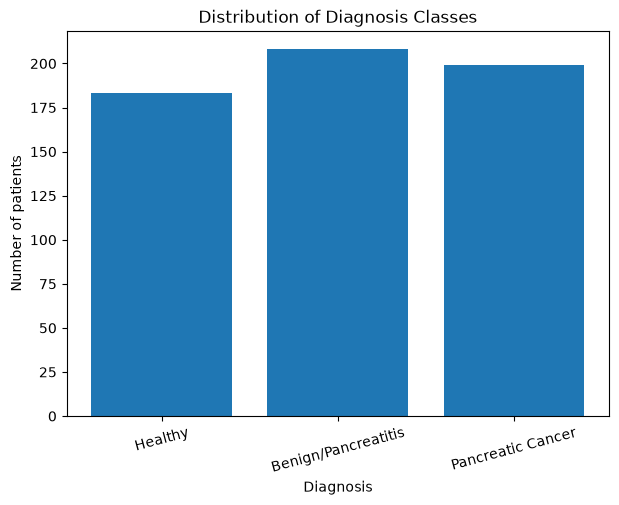

In [ ]:
class_names = [
    "Healthy",
    "Benign/Pancreatitis",
    "Pancreatic Cancer"
]
counts = df["diagnosis"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(class_names, counts)

plt.xlabel("Diagnosis")
plt.ylabel("Number of patients")
plt.title("Distribution of Diagnosis Classes")
plt.xticks(rotation=15)
plt.show()

In [ ]:
df.groupby("diagnosis")["age"].describe()

,count,mean,std,min,25%,50%,75%,max
diagnosis,,,,,,,,
0,183.0,56.333333,12.202654,26.0,48.5,57.0,63.0,89.0
1,208.0,54.701923,13.343387,26.0,44.0,54.0,66.0,82.0
2,199.0,66.180905,10.509132,29.0,59.0,67.0,74.0,88.0


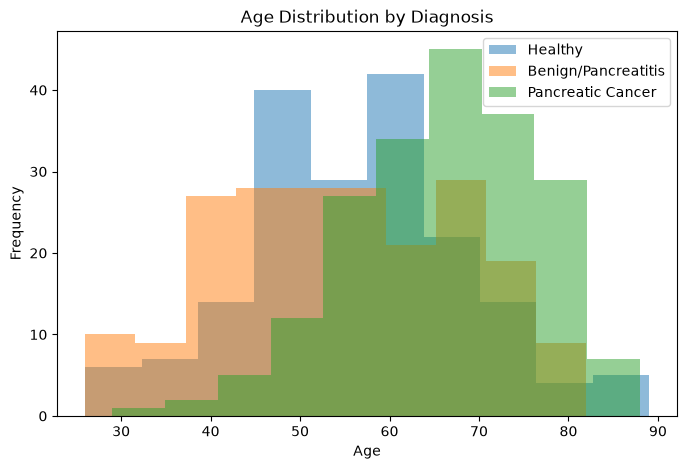

In [ ]:
plt.figure(figsize=(8, 5))

for diagnosis in sorted(df["diagnosis"].dropna().unique()):
    data = df.loc[df["diagnosis"] == diagnosis, "age"].dropna()
    plt.hist(data, alpha=0.5, label=class_names[int(diagnosis)])

plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Age Distribution by Diagnosis")
plt.legend()
plt.show()

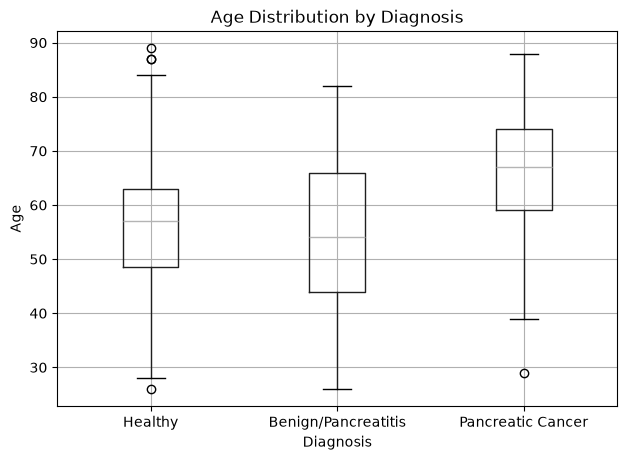

In [ ]:
df.boxplot(
    column="age",
    by="diagnosis",
    figsize=(7, 5)
)

plt.title("Age Distribution by Diagnosis")
plt.suptitle("")
plt.xlabel("Diagnosis")
plt.ylabel("Age")
plt.xticks(
    [1, 2, 3],
    class_names
)
plt.show()

In [ ]:
biomarkers = [
    "plasma_CA19_9",
    "creatinine",
    "LYVE1",
    "REG1B",
    "TFF1",
    "REG1A"
]
df.groupby("diagnosis")[biomarkers].median()



,plasma_CA19_9,creatinine,LYVE1,REG1B,TFF1,REG1A
diagnosis,,,,,,
0,5.334598,0.71253,0.145589,17.58337,59.79300,113.000
1,17.000000,0.74646,1.212167,20.15500,210.21305,127.174
2,427.500000,0.72384,5.621266,123.10473,722.52300,411.006


In [ ]:
df.groupby("diagnosis")[biomarkers].mean()

df.groupby("diagnosis")[biomarkers].describe()

plasma_CA19_9                                                        \
                  count         mean          std  min        25%         50%   
diagnosis                                                                       
0                  92.0     8.749569    12.189355  0.0   1.707332    5.334598   
1                 108.0    61.785741   235.816534  1.0   9.750000   17.000000   
2                 150.0  1476.154733  3550.038158  0.6  99.700000  427.500000   

                            creatinine            ...         TFF1  \
               75%      max      count      mean  ...          75%   
diagnosis                                         ...                
0             9.15     84.3      183.0  0.797633  ...   247.683901   
1            29.25   1913.0      208.0  0.847929  ...   658.550050   
2          1457.50  31000.0      199.0  0.916281  ...  1403.359718   

                         REG1A                                            \
                    max  count         mean          std  min        25%   
diagnosis                                                                  
0           1876.588322   79.0   227.871886   288.272476  0.0   62.15350   
1           4461.684000   87.0   547.458092  1210.159890  0.0   63.54550   
2          13344.300000  140.0  1138.323721  1871.810807  0.0  152.33625   

                                           
               50%         75%        max  
diagnosis                                  
0          113.000   285.60700   1617.142  
1          127.174   405.43800   8083.492  
2          411.006  1435.60625  13200.000  

[3 rows x 48 columns]

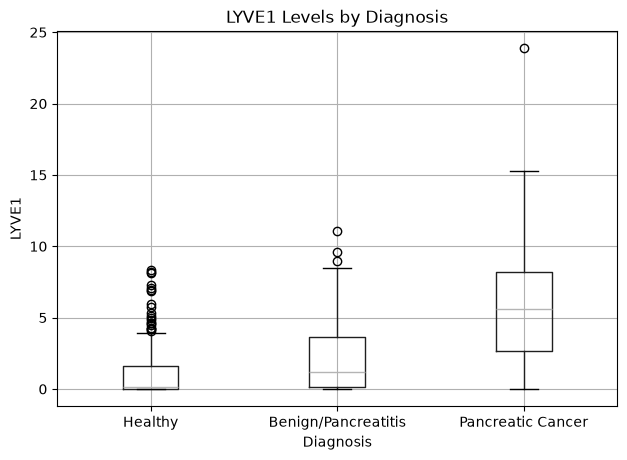

In [ ]:
df.boxplot(
    column="LYVE1",
    by="diagnosis",
    figsize=(7, 5)
)

plt.title("LYVE1 Levels by Diagnosis")
plt.suptitle("")
plt.xlabel("Diagnosis")
plt.ylabel("LYVE1")
plt.xticks([1, 2, 3], class_names)

plt.show()

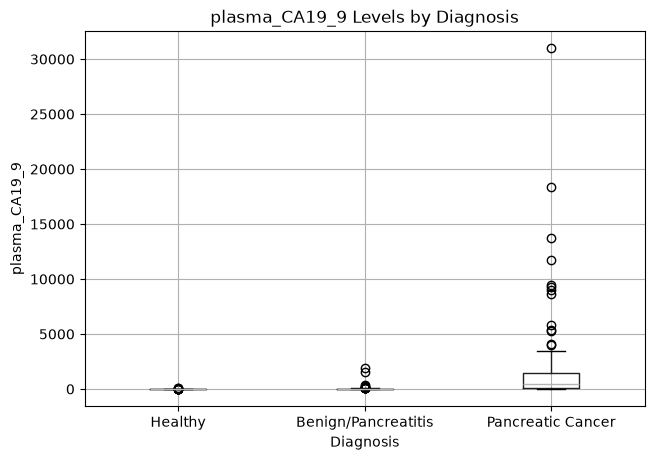

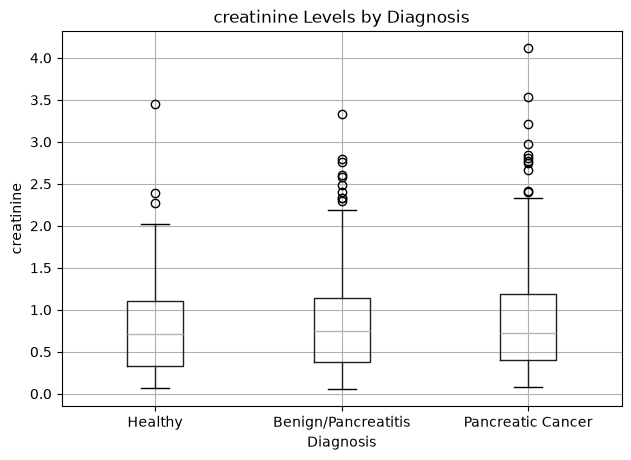

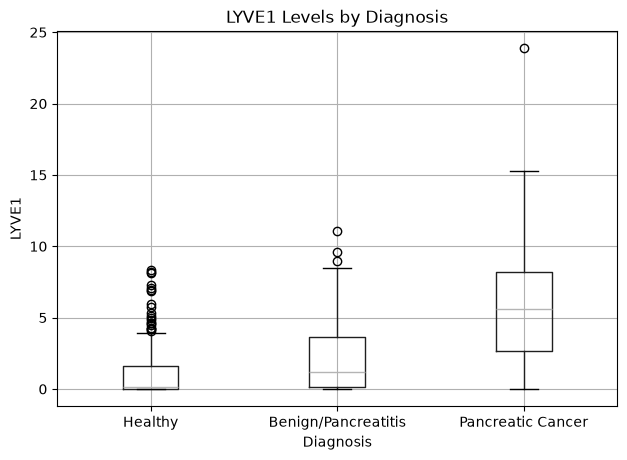

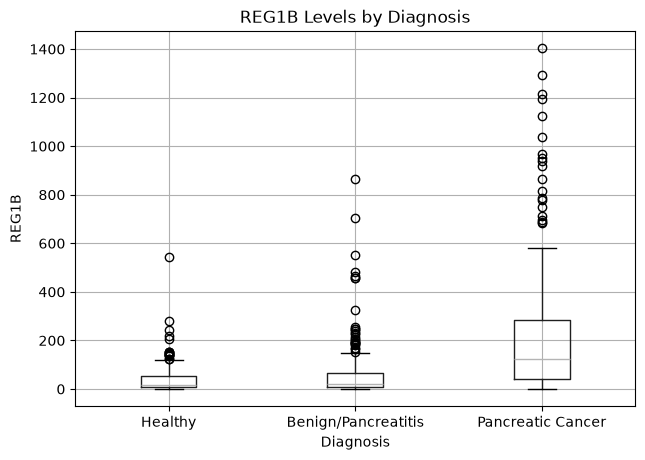

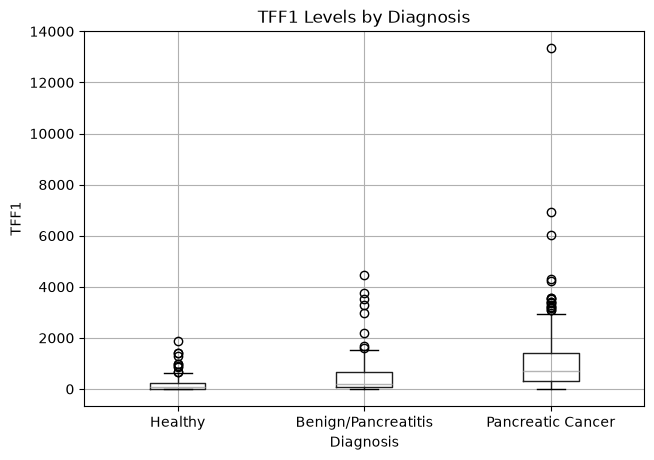

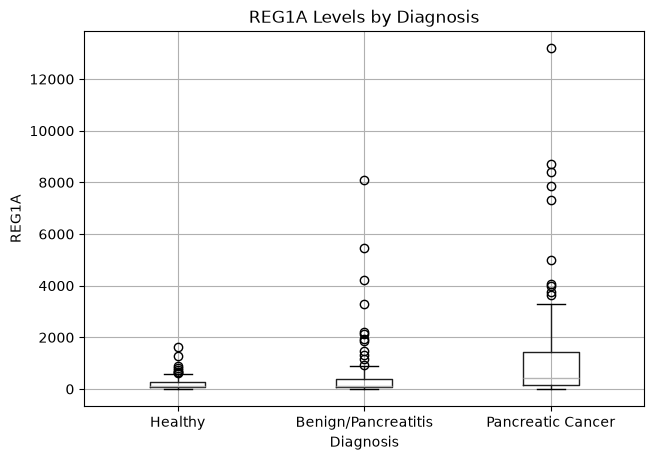

In [ ]:
#Loop through each biomarker and create boxplots for each one
for biomarker in biomarkers:

    df.boxplot(
        column=biomarker,
        by="diagnosis",
        figsize=(7, 5)
    )

    plt.title(f"{biomarker} Levels by Diagnosis")
    plt.suptitle("")
    plt.xlabel("Diagnosis")
    plt.ylabel(biomarker)
    plt.xticks([1, 2, 3], class_names)

    plt.show()

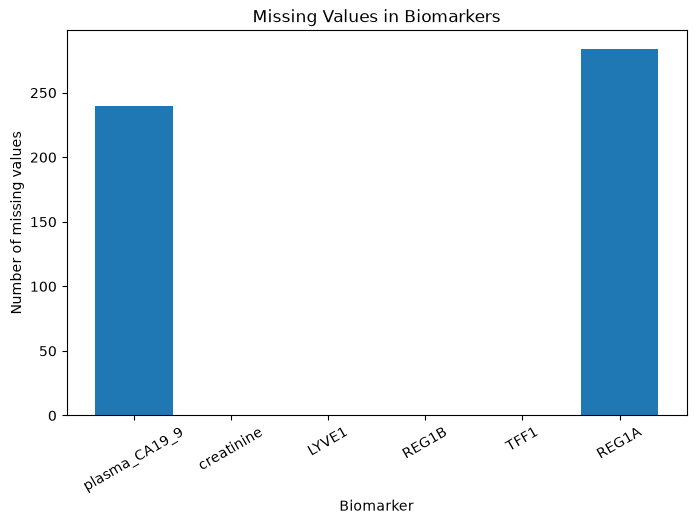

In [ ]:
# Check for missing values in the biomarkers columns
missing = df[biomarkers].isna().sum()

plt.figure(figsize=(8, 5))
plt.bar(missing.index, missing.values)

plt.xlabel("Biomarker")
plt.ylabel("Number of missing values")
plt.title("Missing Values in Biomarkers")
plt.xticks(rotation=30)

plt.show()

In [ ]:
# Check for missing values in the biomarkers columns by diagnosis
missing_by_diagnosis = (
    df.groupby("diagnosis")[biomarkers]
    .apply(lambda x: x.isna().mean() * 100)
)

missing_by_diagnosis

,plasma_CA19_9,creatinine,LYVE1,REG1B,TFF1,REG1A
diagnosis,,,,,,
0,49.726776,0.0,0.0,0.0,0.0,56.830601
1,48.076923,0.0,0.0,0.0,0.0,58.173077
2,24.623116,0.0,0.0,0.0,0.0,29.648241


In [ ]:
# investigate missing values in biomarkers columns by diagnosis column
correlation = df[biomarkers].corr()

print(correlation)

               plasma_CA19_9  creatinine     LYVE1     REG1B      TFF1  \
plasma_CA19_9       1.000000   -0.029418  0.257115  0.175814  0.150694   
creatinine         -0.029418    1.000000  0.338533  0.261906  0.397795   
LYVE1               0.257115    0.338533  1.000000  0.543075  0.577363   
REG1B               0.175814    0.261906  0.543075  1.000000  0.690228   
TFF1                0.150694    0.397795  0.577363  0.690228  1.000000   
REG1A               0.123293    0.060248  0.277696  0.555385  0.418015   

                  REG1A  
plasma_CA19_9  0.123293  
creatinine     0.060248  
LYVE1          0.277696  
REG1B          0.555385  
TFF1           0.418015  
REG1A          1.000000  


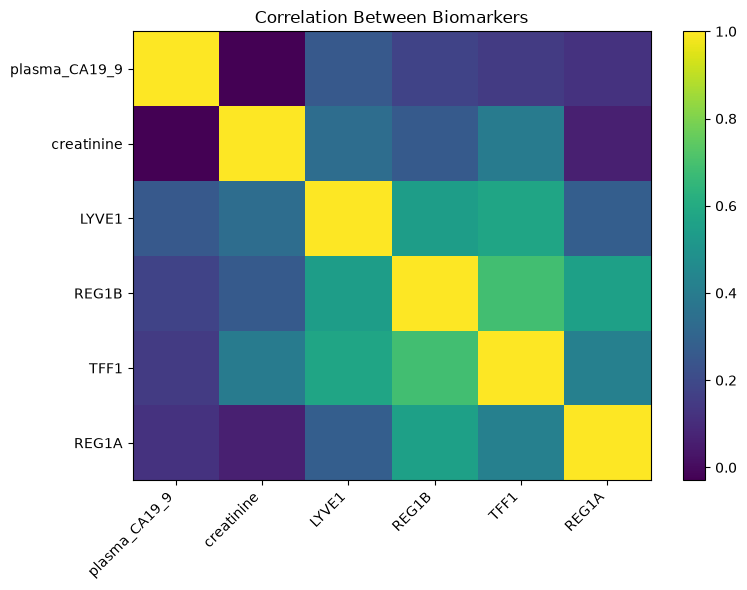

In [ ]:
# visualize the correlation matrix
plt.figure(figsize=(8, 6))

plt.imshow(correlation, aspect="auto")
plt.colorbar()

plt.xticks(
    range(len(biomarkers)),
    biomarkers,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(biomarkers)),
    biomarkers
)

plt.title("Correlation Between Biomarkers")

plt.tight_layout()
plt.show()

In [ ]:
median_by_diagnosis = (
    df.groupby("diagnosis")[biomarkers]
    .median()
)

median_by_diagnosis.index = class_names

median_by_diagnosis

,plasma_CA19_9,creatinine,LYVE1,REG1B,TFF1,REG1A
Healthy,5.334598,0.71253,0.145589,17.58337,59.79300,113.000
Benign/Pancreatitis,17.000000,0.74646,1.212167,20.15500,210.21305,127.174
Pancreatic Cancer,427.500000,0.72384,5.621266,123.10473,722.52300,411.006
